In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np  # Ci servirà più avanti, ma importalo ora

# Carica il tuo dataset
# Assicurati di usare il percorso e il nome corretti del tuo file
try:
    df = pd.read_csv('../data/raw/fc25/all_players.csv')
    print(f"Dataset caricato con successo: {df.shape[0]} righe e {df.shape[1]} colonne.")
except FileNotFoundError:
    print("Errore: File non trovato. Controlla il percorso e il nome del file.")

Dataset caricato con successo: 17737 righe e 58 colonne.


In [2]:
print("Nomi delle colonne:", df.columns.to_list())

Nomi delle colonne: ['Unnamed: 0.1', 'Unnamed: 0', 'Rank', 'Name', 'OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY', 'Acceleration', 'Sprint Speed', 'Positioning', 'Finishing', 'Shot Power', 'Long Shots', 'Volleys', 'Penalties', 'Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing', 'Long Passing', 'Curve', 'Dribbling', 'Agility', 'Balance', 'Reactions', 'Ball Control', 'Composure', 'Interceptions', 'Heading Accuracy', 'Def Awareness', 'Standing Tackle', 'Sliding Tackle', 'Jumping', 'Stamina', 'Strength', 'Aggression', 'Position', 'Weak foot', 'Skill moves', 'Preferred foot', 'Height', 'Weight', 'Alternative positions', 'Age', 'Nation', 'League', 'Team', 'play style', 'url', 'GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning', 'GK Reflexes']


### Esplorazione preliminare del dataset originale

Prima di procedere con la pulizia osserviamo la composizione del dataset e le principali statistiche numeriche. In questa prima tabella i portieri e i giocatori di movimento sono ancora uniti. Il riepilogo rappresenta il punto di partenza dell'esplorazione; nei passaggi successivi controlleremo se le statistiche sintetiche sono coerenti con le caratteristiche dettagliate dei calciatori.

In [3]:
mask_portieri = df['Position'].eq('GK')
df_portieri_grezzi = df.loc[mask_portieri].copy()
df_movimento_grezzi = df.loc[~mask_portieri].copy()

print(f'Giocatori complessivi: {len(df)}')
print(f'Giocatori di movimento: {len(df_movimento_grezzi)}')
print(f'Portieri: {len(df_portieri_grezzi)}')

statistiche_iniziali = [
    'OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY',
    'Age', 'Weak foot', 'Skill moves'
]

df[statistiche_iniziali].describe().round(1)

Giocatori complessivi: 17737
Giocatori di movimento: 15738
Portieri: 1999


,OVR,PAC,SHO,PAS,DRI,DEF,PHY,Age,Weak foot,Skill moves
count,17737.0,17737.0,17737.0,17737.0,17737.0,17737.0,17737.0,17737.0,17737.0,17737.0
mean,66.8,68.2,54.8,59.2,64.2,51.2,65.4,25.7,2.9,2.4
std,7.0,10.6,13.9,9.8,9.4,16.5,9.5,4.6,0.7,0.8
min,47.0,29.0,20.0,25.0,29.0,15.0,32.0,17.0,1.0,1.0
25%,62.0,62.0,46.0,53.0,59.0,37.0,59.0,22.0,3.0,2.0
50%,67.0,69.0,57.0,60.0,65.0,55.0,66.0,25.0,3.0,2.0
75%,71.0,75.0,65.0,66.0,70.0,64.0,72.0,29.0,3.0,3.0
max,91.0,97.0,93.0,94.0,92.0,91.0,91.0,44.0,5.0,5.0


Il riepilogo complessivo non consente di capire se le statistiche sintetiche sono coerenti con le caratteristiche dettagliate dei calciatori. Per ricostruire l'esplorazione iniziale, confrontiamo ogni statistica sintetica con la media delle componenti che dovrebbe riassumere. Il confronto viene svolto separatamente per portieri e giocatori di movimento, senza avere ancora eliminato o rinominato alcuna colonna.

In [4]:
componenti_statistiche = {
    'PAC': ['Acceleration', 'Sprint Speed'],
    'SHO': ['Positioning', 'Finishing', 'Shot Power', 'Long Shots', 'Volleys', 'Penalties'],
    'PAS': ['Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing', 'Long Passing', 'Curve'],
    'DRI': ['Dribbling', 'Agility', 'Balance', 'Reactions', 'Ball Control', 'Composure'],
    'DEF': ['Interceptions', 'Heading Accuracy', 'Def Awareness', 'Standing Tackle', 'Sliding Tackle'],
    'PHY': ['Jumping', 'Stamina', 'Strength', 'Aggression']
}

gruppi_giocatori = {
    'Giocatori di movimento': df_movimento_grezzi,
    'Portieri': df_portieri_grezzi
}

righe_confronto = []
for nome_gruppo, dati_gruppo in gruppi_giocatori.items():
    for statistica_sintetica, colonne_dettaglio in componenti_statistiche.items():
        media_dettaglio_giocatore = dati_gruppo[colonne_dettaglio].mean(axis=1)
        righe_confronto.append({
            'Gruppo': nome_gruppo,
            'Statistica': statistica_sintetica,
            'Media sintetica': dati_gruppo[statistica_sintetica].mean(),
            'Media componenti dettagliate': media_dettaglio_giocatore.mean(),
            'Correlazione': dati_gruppo[statistica_sintetica].corr(media_dettaglio_giocatore),
            'Differenza media assoluta': (dati_gruppo[statistica_sintetica] - media_dettaglio_giocatore).abs().mean()
        })

confronto_sintetiche_dettagliate = pd.DataFrame(righe_confronto).round({
    'Media sintetica': 2,
    'Media componenti dettagliate': 2,
    'Correlazione': 3,
    'Differenza media assoluta': 2
})

confronto_sintetiche_dettagliate

,Gruppo,Statistica,Media sintetica,Media componenti dettagliate,Correlazione,Differenza media assoluta
0,Giocatori di movimento,PAC,68.54,68.52,0.999,0.30
1,Giocatori di movimento,SHO,53.69,53.35,0.991,1.75
2,Giocatori di movimento,PAS,58.66,55.76,0.980,3.05
3,Giocatori di movimento,DRI,63.88,64.37,0.964,2.04
4,Giocatori di movimento,DEF,53.18,53.39,0.996,1.39
5,Giocatori di movimento,PHY,65.55,65.58,0.982,1.42
6,Portieri,PAC,65.88,35.86,0.461,30.02
7,Portieri,SHO,63.91,17.86,0.536,46.05
8,Portieri,PAS,63.02,23.04,0.515,39.98
9,Portieri,DRI,66.75,34.89,0.612,31.85


In [5]:
# Un esempio dell'anomalia: PAC elevato ma valori dettagliati di velocità molto più bassi
esempio_anomalia_pac = df.loc[
    df['Position'].eq('GK'),
    ['Name', 'PAC', 'Acceleration', 'Sprint Speed']
].copy()
esempio_anomalia_pac['Media velocità dettagliata'] = esempio_anomalia_pac[
    ['Acceleration', 'Sprint Speed']
].mean(axis=1)
esempio_anomalia_pac['Differenza'] = (
    esempio_anomalia_pac['PAC'] - esempio_anomalia_pac['Media velocità dettagliata']
)

esempio_anomalia_pac.nlargest(8, 'Differenza').round(1).reset_index(drop=True)

,Name,PAC,Acceleration,Sprint Speed,Media velocità dettagliata,Differenza
0,Jacob Widell Zetterström,78,16,27,21.5,56.5
1,Wladimiro Falcone,83,26,28,27.0,56.0
2,Ismael Diawara,72,19,16,17.5,54.5
3,Carlos Miguel,71,18,16,17.0,54.0
4,Moritz Nicolas,76,18,26,22.0,54.0
5,Dionne van der Wal,71,18,17,17.5,53.5
6,Predrag Rajković,77,30,18,24.0,53.0
7,Aleš Mandous,72,20,18,19.0,53.0


In [6]:
# Il tiro presenta lo scarto più evidente tra valore sintetico e componenti dettagliate
componenti_tiro = [
    'Positioning', 'Finishing', 'Shot Power',
    'Long Shots', 'Volleys', 'Penalties'
]
esempio_anomalia_sho = df.loc[
    df['Position'].eq('GK'),
    ['Name', 'SHO'] + componenti_tiro
].copy()
esempio_anomalia_sho['Media tiro dettagliata'] = esempio_anomalia_sho[
    componenti_tiro
].mean(axis=1)
esempio_anomalia_sho['Differenza'] = (
    esempio_anomalia_sho['SHO'] - esempio_anomalia_sho['Media tiro dettagliata']
)

esempio_anomalia_sho.nlargest(8, 'Differenza').round(1).reset_index(drop=True)

,Name,SHO,Positioning,Finishing,Shot Power,Long Shots,Volleys,Penalties,Media tiro dettagliata,Differenza
0,Jan Oblak,90,11,11,59,12,13,11,19.5,70.5
1,Gregor Kobel,86,10,10,55,10,10,12,17.8,68.2
2,Giorgi Mamardashvili,83,8,9,54,7,7,11,16.0,67.0
3,Aubrey Kingsbury,82,13,8,53,5,7,11,16.2,65.8
4,Thibaut Courtois,89,13,14,57,17,12,27,23.3,65.7
5,Merle Frohms,82,7,8,57,7,7,18,17.3,64.7
6,Chiamaka Nnadozie,83,14,11,60,9,7,13,19.0,64.0
7,Ann-Katrin Berger,84,9,7,60,6,6,35,20.5,63.5


### Evidenza grafica dell'anomalia

Nei giocatori di movimento le medie delle statistiche sintetiche sono molto vicine alle medie delle rispettive componenti dettagliate. Per i portieri, invece, le due misure sono nettamente distanti: le statistiche sintetiche non stanno quindi riassumendo accelerazione, tiro, passaggio, dribbling, difesa e fisicità nello stesso modo.

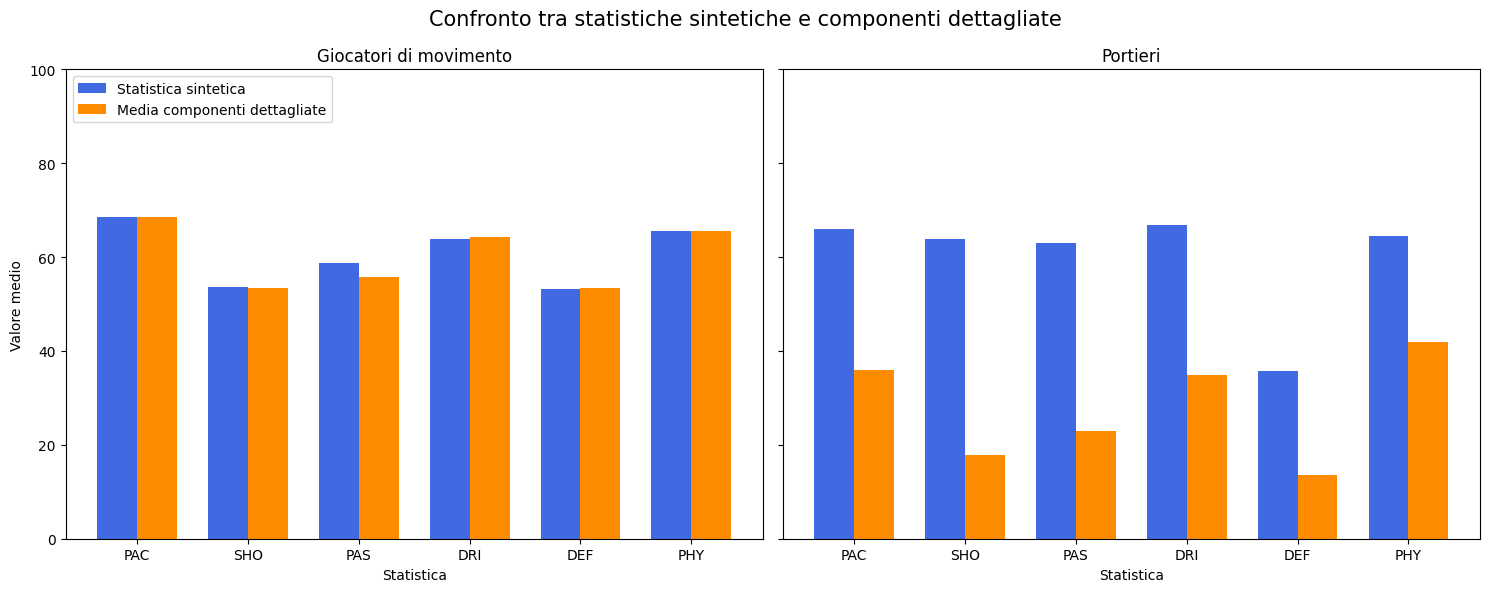

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
colori = ['royalblue', 'darkorange']

for ax, (nome_gruppo, dati_grafico) in zip(
    axes, confronto_sintetiche_dettagliate.groupby('Gruppo', sort=False)
):
    posizioni = np.arange(len(dati_grafico))
    larghezza = 0.36
    ax.bar(
        posizioni - larghezza / 2, dati_grafico['Media sintetica'],
        width=larghezza, label='Statistica sintetica', color=colori[0]
    )
    ax.bar(
        posizioni + larghezza / 2, dati_grafico['Media componenti dettagliate'],
        width=larghezza, label='Media componenti dettagliate', color=colori[1]
    )
    ax.set_title(nome_gruppo)
    ax.set_xticks(posizioni)
    ax.set_xticklabels(dati_grafico['Statistica'])
    ax.set_xlabel('Statistica')
    ax.set_ylim(0, 100)

axes[0].set_ylabel('Valore medio')
axes[0].legend(loc='upper left')
fig.suptitle('Confronto tra statistiche sintetiche e componenti dettagliate', fontsize=15)
plt.tight_layout()
plt.show()

### Individuazione della mappatura delle statistiche dei portieri

L'incoerenza emersa suggerisce che, nelle righe dei portieri, le statistiche sintetiche contengano informazioni diverse da quelle indicate dal loro nome. Affiancando le colonne originali si osserva che `PAC`, `SHO`, `PAS`, `DRI` e `PHY` riprendono direttamente cinque caratteristiche specifiche dei portieri. La verifica successiva controlla questa ipotesi su tutte le righe del gruppo.

Nel file originale non è presente una colonna denominata `GK Speed` con cui confrontare direttamente `DEF`. Per questo motivo, nella successiva preparazione dei dati `DEF` viene conservata per i portieri e rinominata `GK Speed`.

In [8]:
# Esempio dei valori originali, prima di qualsiasi rinomina
colonne_confronto_mappatura = [
    'Name', 'PAC', 'GK Diving', 'SHO', 'GK Handling',
    'PAS', 'GK Kicking', 'DRI', 'GK Reflexes',
    'PHY', 'GK Positioning', 'DEF'
]

df_portieri_grezzi[colonne_confronto_mappatura].head(5)

,Name,PAC,GK Diving,SHO,GK Handling,PAS,GK Kicking,DRI,GK Reflexes,PHY,GK Positioning,DEF
8,Gianluigi Donnarumma,90,90.0,84,84.0,73,73.0,90,90.0,87,87.0,52
9,Alisson,86,86.0,85,85.0,85,85.0,89,89.0,90,90.0,56
10,Thibaut Courtois,85,85.0,89,89.0,76,76.0,90,90.0,88,88.0,46
13,Marc-André ter Stegen,86,86.0,85,85.0,89,89.0,91,91.0,86,86.0,47
21,Ederson,87,87.0,82,82.0,91,91.0,87,87.0,86,86.0,64


In [9]:
# Verifica delle corrispondenze tra statistiche sintetiche e statistiche dei portieri
mask_portieri = df['Position'].eq('GK')

mappatura_portieri = {
    'PAC': 'GK Diving',
    'SHO': 'GK Handling',
    'PAS': 'GK Kicking',
    'DRI': 'GK Reflexes',
    'PHY': 'GK Positioning'
}

righe_verifica = []
for statistica_sintetica, statistica_gk in mappatura_portieri.items():
    valori_sintetici = df.loc[mask_portieri, statistica_sintetica]
    valori_gk = df.loc[mask_portieri, statistica_gk]
    valori_validi = valori_sintetici.notna() & valori_gk.notna()
    coincidenze = valori_sintetici[valori_validi].eq(valori_gk[valori_validi]).sum()
    totale_confrontato = valori_validi.sum()

    righe_verifica.append({
        'Statistica sintetica': statistica_sintetica,
        'Significato per i portieri': statistica_gk,
        'Valori confrontati': totale_confrontato,
        'Valori coincidenti': coincidenze,
        'Corrispondenza (%)': round(coincidenze / totale_confrontato * 100, 2)
    })

verifica_mappatura = pd.DataFrame(righe_verifica)
verifica_mappatura

,Statistica sintetica,Significato per i portieri,Valori confrontati,Valori coincidenti,Corrispondenza (%)
0,PAC,GK Diving,1999,1999,100.0
1,SHO,GK Handling,1999,1999,100.0
2,PAS,GK Kicking,1999,1999,100.0
3,DRI,GK Reflexes,1999,1999,100.0
4,PHY,GK Positioning,1999,1999,100.0


### Confronto delle statistiche dettagliate

Le colonne dettagliate mantengono lo stesso nome per tutti i calciatori, ma descrivono abilità tipiche del gioco di movimento. Il confronto seguente mostra quanto siano diversi i valori dei due gruppi.

In [10]:
# Confronto tra alcune statistiche dettagliate dei due gruppi
statistiche_dettaglio = [
    'Acceleration', 'Sprint Speed', 'Positioning', 'Finishing',
    'Long Shots', 'Dribbling', 'Ball Control', 'Stamina'
]

confronto_dettaglio = pd.DataFrame({
    'Portieri - media': df.loc[mask_portieri, statistiche_dettaglio].mean(),
    'Portieri - mediana': df.loc[mask_portieri, statistiche_dettaglio].median(),
    'Movimento - media': df.loc[~mask_portieri, statistiche_dettaglio].mean(),
    'Movimento - mediana': df.loc[~mask_portieri, statistiche_dettaglio].median()
}).round(2)

confronto_dettaglio.index.name = 'Statistica'
confronto_dettaglio

,Portieri - media,Portieri - mediana,Movimento - media,Movimento - mediana
Statistica,,,,
Acceleration,35.62,35.0,68.52,69.0
Sprint Speed,36.11,36.0,68.52,69.0
Positioning,9.62,9.0,56.90,59.0
Finishing,10.38,9.0,52.13,55.0
Long Shots,10.86,10.0,52.27,55.0
Dribbling,13.09,12.0,62.41,64.0
Ball Control,19.29,18.0,64.92,65.0
Stamina,28.30,28.0,67.91,69.0


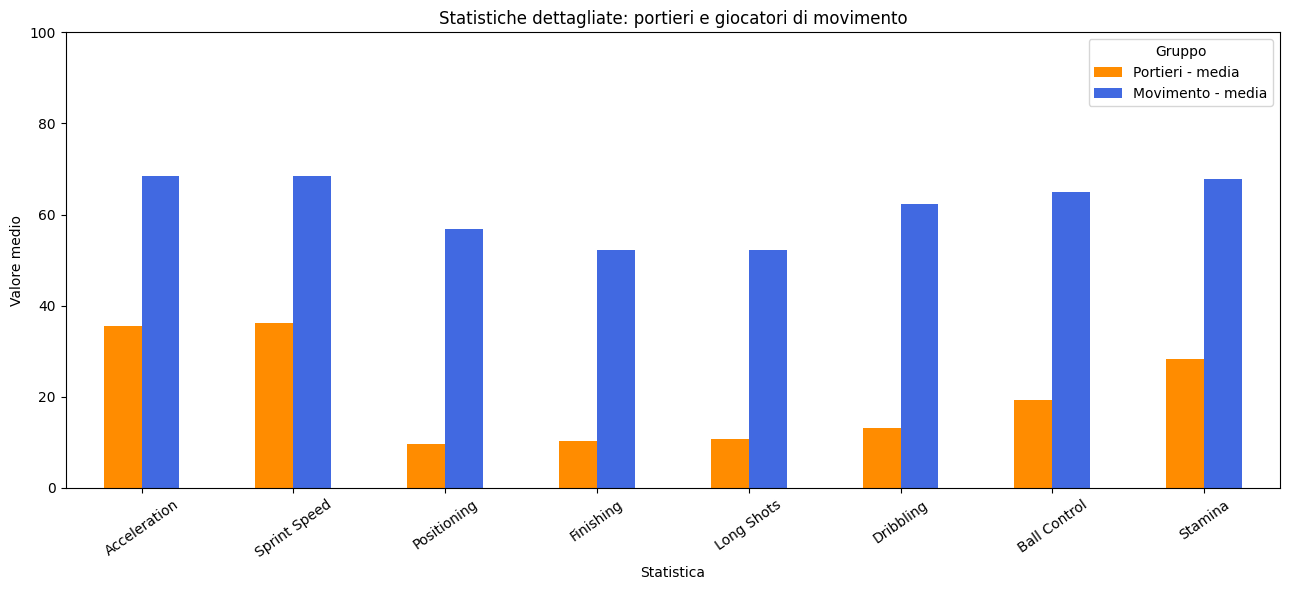

In [11]:
# Confronto grafico delle medie delle statistiche dettagliate
confronto_medie = confronto_dettaglio[['Portieri - media', 'Movimento - media']]
ax = confronto_medie.plot(kind='bar', figsize=(13, 6), color=['darkorange', 'royalblue'])
ax.set_title('Statistiche dettagliate: portieri e giocatori di movimento')
ax.set_xlabel('Statistica')
ax.set_ylabel('Valore medio')
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=35)
ax.legend(title='Gruppo')
plt.tight_layout()
plt.show()

Le cinque corrispondenze risultano valide per tutti i portieri. I valori non sono quindi errati, ma assumono un significato diverso in base al ruolo. Anche le statistiche dettagliate legate al gioco di movimento presentano valori molto più bassi per i portieri. Analizzare insieme i due gruppi potrebbe quindi produrre confronti poco significativi: per questo motivo il dataset viene suddiviso in portieri e giocatori di movimento prima delle analisi successive.

### DATAFRAME SEPARATI 

In [12]:
# Definisci le tue variabili (facilita la lettura)
colonna_posizione = 'Position'
sigla_portiere = 'GK'

# 1. Creare il DataFrame dei Portieri
# Seleziona tutte le righe dove il valore di 'colonna_posizione' è UGUALE a 'sigla_portiere'
df_portieri = df[df[colonna_posizione] == sigla_portiere].copy()

# 2. Creare il DataFrame dei Giocatori di Movimento
# Seleziona tutte le righe dove il valore di 'colonna_posizione' è DIVERSO da 'sigla_portiere'
df_movimento = df[df[colonna_posizione] != sigla_portiere].copy()

In [13]:
print(f"\n--- Verifica Separazione ---")

# Controlla il DataFrame dei portieri
print(f"Numero totale di portieri: {len(df_portieri)}")
# Stampa le posizioni uniche per essere sicuro
print(f"Posizioni trovate nel df_portieri: {df_portieri[colonna_posizione].unique()}")

# Controlla il DataFrame dei giocatori di movimento
print(f"Numero totale di giocatori di movimento: {len(df_movimento)}")
# Stampa le posizioni uniche per essere sicuro
print(f"Posizioni trovate nel df_movimento: {df_movimento[colonna_posizione].unique()}")

# Controllo finale: la somma deve fare il totale
print(f"Controllo: {len(df_portieri)} + {len(df_movimento)} = {len(df_portieri) + len(df_movimento)}")
print(f"Righe totali originali: {len(df)}")


--- Verifica Separazione ---
Numero totale di portieri: 1999
Posizioni trovate nel df_portieri: ['GK']
Numero totale di giocatori di movimento: 15738
Posizioni trovate nel df_movimento: ['ST' 'CDM' 'CAM' 'LW' 'CM' 'CB' 'RW' 'LB' 'LM' 'RB' 'RM']
Controllo: 1999 + 15738 = 17737
Righe totali originali: 17737


### PULIZIA COLONNE

### Giocatori Movimento

In [14]:
# Colonne specifiche dei portieri (piene di NaN)
colonne_stats_gk = ['GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning', 'GK Reflexes']

# Colonne "spazzatura" 
colonne_inutili = ['Unnamed: 0.1', 'Unnamed: 0', 'Rank', 'url']

# Combiniamo le liste
colonne_da_droppare_movimento = colonne_stats_gk + colonne_inutili

# Applichiamo il .drop()
df_movimento_pulito = df_movimento.drop(columns=colonne_da_droppare_movimento)

### Portieri

In [15]:
# --- CREAZIONE df_portieri_pulito (Versione Finale) ---

# 1. (Richiesta 1) Definiamo le colonne "generali" da TENERE
#    NOTA: 'Alternative positions' è stata esclusa da questa lista.
colonne_generali = [
    'Name', 'OVR', 'Position', 'Age', 'Nation', 'League', 'Team', 
    'Height', 'Weight', 'Preferred foot', 'Weak foot', 'Skill moves',
    'play style'
]

# 2. Definiamo le statistiche VERE da tenere
colonne_stats_portiere_vere = [
    'GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning', 'GK Reflexes'
]
colonna_velocita_gk = ['DEF'] # La teniamo temporaneamente con questo nome

# 3. Creiamo un DataFrame temporaneo con solo le colonne che ci servono
colonne_da_tenere = colonne_generali + colonne_stats_portiere_vere + colonna_velocita_gk
df_portieri_temp = df_portieri[colonne_da_tenere].copy()

# 4. (Richiesta 2) Rinominiamo 'DEF' in 'GK Speed'
df_portieri_temp = df_portieri_temp.rename(columns={'DEF': 'GK Speed'})

# 5. (Richiesta 3) Definiamo l'ORDINE FINALE delle colonne
#    Mettiamo le 6 statistiche chiave subito dopo 'Position'
colonne_ordine_finale = [
    'Name', 'OVR',  
    'GK Diving', 'GK Handling', 'GK Kicking', 'GK Reflexes', 'GK Speed', 'GK Positioning', 
    'Position', 'Age', 'Nation', 'League', 'Team', 'Height', 'Weight', 
    'Preferred foot', 'Weak foot', 'Skill moves', 'play style'
]


# 6. Creiamo il DataFrame finale pulito applicando il nuovo ordine
df_portieri_pulito = df_portieri_temp[colonne_ordine_finale]

# --- VERIFICA FINALE ---
print("--- df_portieri_pulito (Verificato e Riorganizzato) ---")
print(f"Numero di colonne: {len(df_portieri_pulito.columns)}")
df_portieri_pulito.head()

--- df_portieri_pulito (Verificato e Riorganizzato) ---
Numero di colonne: 19


,Name,OVR,GK Diving,GK Handling,GK Kicking,GK Reflexes,GK Speed,GK Positioning,Position,Age,Nation,League,Team,Height,Weight,Preferred foot,Weak foot,Skill moves,play style
8,Gianluigi Donnarumma,89,90.0,84.0,73.0,90.0,52,87.0,GK,25,Italy,Ligue 1 McDonald's,Paris SG,"196cm / 6'5""",90kg / 198lb,Right,3,1,"Deflector+, Footwork"
9,Alisson,89,86.0,85.0,85.0,89.0,56,90.0,GK,31,Brazil,Premier League,Liverpool,"193cm / 6'4""",91kg / 201lb,Right,3,1,"Deflector+, 1v1 Close Down, Far Throw"
10,Thibaut Courtois,89,85.0,89.0,76.0,90.0,46,88.0,GK,32,Belgium,LALIGA EA SPORTS,Real Madrid,"200cm / 6'7""",96kg / 212lb,Left,3,1,"1v1 Close Down+, Cross Claimer, Far Throw"
13,Marc-André ter Stegen,89,86.0,85.0,89.0,91.0,47,86.0,GK,32,Germany,LALIGA EA SPORTS,FC Barcelona,"187cm / 6'2""",85kg / 187lb,Right,4,1,"Footwork+, 1v1 Close Down"
21,Ederson,88,87.0,82.0,91.0,87.0,64,86.0,GK,31,Brazil,Premier League,Manchester City,"188cm / 6'2""",86kg / 190lb,Left,3,1,"Long Ball Pass+, Cross Claimer, Pinged Pass"


In [16]:
print("--- 1. VERIFICA PORTIERI (df_portieri_pulito) ---")

# 1A. Controllo Colonne
print("\n[Controllo Colonne (info)]: ")
df_portieri_pulito.info()

# 1B. Controllo Righe (Corretto: 'Position' singolare)
print("\n[Controllo Righe (Position)]: ")
print(df_portieri_pulito['Position'].value_counts())

# 1C. Ispezione visiva
print("\n[Ispezione prime 5 righe]: ")
df_portieri_pulito.head()

--- 1. VERIFICA PORTIERI (df_portieri_pulito) ---

[Controllo Colonne (info)]: 
<class 'pandas.core.frame.DataFrame'>
Index: 1999 entries, 8 to 17722
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Name            1999 non-null   object 
 1   OVR             1999 non-null   int64  
 2   GK Diving       1999 non-null   float64
 3   GK Handling     1999 non-null   float64
 4   GK Kicking      1999 non-null   float64
 5   GK Reflexes     1999 non-null   float64
 6   GK Speed        1999 non-null   int64  
 7   GK Positioning  1999 non-null   float64
 8   Position        1999 non-null   object 
 9   Age             1999 non-null   int64  
 10  Nation          1999 non-null   object 
 11  League          1999 non-null   object 
 12  Team            1999 non-null   object 
 13  Height          1999 non-null   object 
 14  Weight          1999 non-null   object 
 15  Preferred foot  1999 non-null   object 
 16  We

,Name,OVR,GK Diving,GK Handling,GK Kicking,GK Reflexes,GK Speed,GK Positioning,Position,Age,Nation,League,Team,Height,Weight,Preferred foot,Weak foot,Skill moves,play style
8,Gianluigi Donnarumma,89,90.0,84.0,73.0,90.0,52,87.0,GK,25,Italy,Ligue 1 McDonald's,Paris SG,"196cm / 6'5""",90kg / 198lb,Right,3,1,"Deflector+, Footwork"
9,Alisson,89,86.0,85.0,85.0,89.0,56,90.0,GK,31,Brazil,Premier League,Liverpool,"193cm / 6'4""",91kg / 201lb,Right,3,1,"Deflector+, 1v1 Close Down, Far Throw"
10,Thibaut Courtois,89,85.0,89.0,76.0,90.0,46,88.0,GK,32,Belgium,LALIGA EA SPORTS,Real Madrid,"200cm / 6'7""",96kg / 212lb,Left,3,1,"1v1 Close Down+, Cross Claimer, Far Throw"
13,Marc-André ter Stegen,89,86.0,85.0,89.0,91.0,47,86.0,GK,32,Germany,LALIGA EA SPORTS,FC Barcelona,"187cm / 6'2""",85kg / 187lb,Right,4,1,"Footwork+, 1v1 Close Down"
21,Ederson,88,87.0,82.0,91.0,87.0,64,86.0,GK,31,Brazil,Premier League,Manchester City,"188cm / 6'2""",86kg / 190lb,Left,3,1,"Long Ball Pass+, Cross Claimer, Pinged Pass"


In [17]:
# --- 6. CONVERSIONE TIPO DI DATO (da float a int) ---
#    (Questo blocco va DOPO il blocco 4 e 5)

# 1. Definiamo le 6 statistiche dei portieri che vogliamo convertire
statistiche_gk_da_convertire = [
    'GK Speed', 'GK Diving', 'GK Handling', 
    'GK Kicking', 'GK Positioning', 'GK Reflexes'
]

# 2. Creiamo un dizionario di conversione
#    Questo dice a Pandas: "voglio che 'GK Speed' sia 'int', 'GK Diving' sia 'int', ecc."
conversion_dict = {col: int for col in statistiche_gk_da_convertire}

# 3. Applichiamo la conversione
#    Usiamo .astype() per applicare il nostro dizionario.
#    Questo è il modo più pulito e sicuro per farlo.
df_portieri_pulito = df_portieri_pulito.astype(conversion_dict)

# --- 7. VERIFICA FINALE TIPO DATI ---
print("\n--- Verifica Tipi di Dato (Portieri) ---")
# Ora nell'output di .info() dovresti vedere 'int64' per le 6 statistiche,
# invece di 'float64'.
df_portieri_pulito.info()


--- Verifica Tipi di Dato (Portieri) ---
<class 'pandas.core.frame.DataFrame'>
Index: 1999 entries, 8 to 17722
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Name            1999 non-null   object
 1   OVR             1999 non-null   int64 
 2   GK Diving       1999 non-null   int64 
 3   GK Handling     1999 non-null   int64 
 4   GK Kicking      1999 non-null   int64 
 5   GK Reflexes     1999 non-null   int64 
 6   GK Speed        1999 non-null   int64 
 7   GK Positioning  1999 non-null   int64 
 8   Position        1999 non-null   object
 9   Age             1999 non-null   int64 
 10  Nation          1999 non-null   object
 11  League          1999 non-null   object
 12  Team            1999 non-null   object
 13  Height          1999 non-null   object
 14  Weight          1999 non-null   object
 15  Preferred foot  1999 non-null   object
 16  Weak foot       1999 non-null   int64 
 17  Skill moves   

In [18]:
df_portieri_pulito.head()

,Name,OVR,GK Diving,GK Handling,GK Kicking,GK Reflexes,GK Speed,GK Positioning,Position,Age,Nation,League,Team,Height,Weight,Preferred foot,Weak foot,Skill moves,play style
8,Gianluigi Donnarumma,89,90,84,73,90,52,87,GK,25,Italy,Ligue 1 McDonald's,Paris SG,"196cm / 6'5""",90kg / 198lb,Right,3,1,"Deflector+, Footwork"
9,Alisson,89,86,85,85,89,56,90,GK,31,Brazil,Premier League,Liverpool,"193cm / 6'4""",91kg / 201lb,Right,3,1,"Deflector+, 1v1 Close Down, Far Throw"
10,Thibaut Courtois,89,85,89,76,90,46,88,GK,32,Belgium,LALIGA EA SPORTS,Real Madrid,"200cm / 6'7""",96kg / 212lb,Left,3,1,"1v1 Close Down+, Cross Claimer, Far Throw"
13,Marc-André ter Stegen,89,86,85,89,91,47,86,GK,32,Germany,LALIGA EA SPORTS,FC Barcelona,"187cm / 6'2""",85kg / 187lb,Right,4,1,"Footwork+, 1v1 Close Down"
21,Ederson,88,87,82,91,87,64,86,GK,31,Brazil,Premier League,Manchester City,"188cm / 6'2""",86kg / 190lb,Left,3,1,"Long Ball Pass+, Cross Claimer, Pinged Pass"


In [19]:

# Salva i giocatori di movimento in un file
df_movimento_pulito.to_csv('../data/puliti/movimento_puliti.csv', index=False)

# Salva i portieri in un altro file
df_portieri_pulito.to_csv('../data/puliti/portieri_puliti.csv', index=False)

print("DataFrame puliti salvati in 'movimento_puliti.csv' e 'portieri_puliti.csv'")

DataFrame puliti salvati in 'movimento_puliti.csv' e 'portieri_puliti.csv'
